In [2]:
import numpy as np
import matplotlib.pyplot as plt

print(f'NumPy version: {np.__version__}')
print('Imports successful.')

NumPy version: 2.1.3
Imports successful.


In [3]:
def generate_sensor_stream(samples=1000, features=3, seed=42):
    """Generates synthetic multivariate time-series baseline sensor data."""
    np.random.seed(seed)
    t = np.linspace(0, 50, samples)
    stream = np.zeros((samples, features))
    for f in range(features):
        stream[:, f] = np.sin(t * (f + 1)) + np.random.normal(0, 0.05, samples)
    return stream

clean_stream = generate_sensor_stream(samples=1000, features=3)
print(f'Clean stream shape: {clean_stream.shape}')   # Expected: (1000, 3)
print(f'Value range: [{clean_stream.min():.3f}, {clean_stream.max():.3f}]')
assert clean_stream.shape == (1000, 3)
print('Shape assertion passed.')

Clean stream shape: (1000, 3)
Value range: [-1.126, 1.157]
Shape assertion passed.


In [4]:
# Simulate SKAB-style anomaly labels: two windows of different lengths
labels = np.zeros(1000, dtype=int)
labels[200:280] = 1    # Window A: 80 timesteps
labels[600:750] = 1    # Window B: 150 timesteps

print(f'Total anomaly rows: {labels.sum()}')
print(f'Anomaly fraction:   {labels.mean():.3f}')
assert labels.sum() == 230
print('Label assertion passed.')

Total anomaly rows: 230
Anomaly fraction:   0.230
Label assertion passed.


In [6]:
def extract_anomaly_windows(anomaly_labels):
    """
    Converts a binary anomaly label array into a list of (start, end) tuples.
    Each contiguous run of 1s becomes one window. End index is exclusive.

    Parameters
    ----------
    anomaly_labels : array-like of 0/1 integers, length T

    Returns
    -------
    windows : list of (start_idx, end_idx) tuples
    """
    windows   = []
    in_window = False
    start     = 0

    # TODO: Walk through anomaly_labels with enumerate()
    # - When you see label==1 and in_window is False: record start, set in_window=True
    # - When you see label==0 and in_window is True: append (start, i) to windows, set in_window=False
    # your code here

    for i, label in enumerate(anomaly_labels):
      if label == 1 and not in_window:
        start = i
        in_window = True

      elif label == 0 and in_window:
        windows.append((start, i))
        in_window = False

    # TODO: Handle the edge case — if in_window is still True at the end of the loop,
    # append (start, len(anomaly_labels)) to windows
    # your code here

    if in_window:
      windows.append((start, len(anomaly_labels)))

    return windows


windows = extract_anomaly_windows(labels)
print(f'Extracted windows: {windows}')

assert len(windows) == 2, f'Expected 2 windows, got {len(windows)}'
assert windows[0] == (200, 280), f'Window A: expected (200, 280), got {windows[0]}'
assert windows[1] == (600, 750), f'Window B: expected (600, 750), got {windows[1]}'
print('Window extraction assertions passed.')

Extracted windows: [(200, 280), (600, 750)]
Window extraction assertions passed.


In [13]:
def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """
    Injects a synthetic noise profile into a localized index window.

    Parameters
    ----------
    raw_data   : np.ndarray, shape (T, F)
    start_idx  : int — first row of the injection window (inclusive)
    end_idx    : int — last row of the injection window (exclusive)
    variance   : float — std dev for mode='noise' (ignored for 'blackout')
    mode       : str — 'noise' or 'blackout'

    Returns
    -------
    poisoned_data : np.ndarray, shape (T, F)
    """
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]

    if mode == 'noise':
         noise = np.random.normal(
             0,
             variance,
              (window_rows, n_features)
              )
         poisoned_data[start_idx:end_idx, :] += noise
        # TODO: Generate Gaussian noise of shape (window_rows, n_features)
        # and add it to poisoned_data[start_idx:end_idx, :]
        # your code here

       # pass

    elif mode == 'blackout':
              poisoned_data[start_idx:end_idx, :] = 0.0

        # TODO: Set poisoned_data[start_idx:end_idx, :] to exactly 0.0
        # your code here
       # pass

    else:
        raise ValueError(f"Unknown mode: '{mode}'. Choose 'noise' or 'blackout'.")

    return poisoned_data


# Apply to both windows, both modes
np.random.seed(42)
noisy_stream    = clean_stream.copy()
blackout_stream = clean_stream.copy()

for start, end in windows:
    noisy_stream    = inject_noise_profile(noisy_stream,    start, end, variance=2.5, mode='noise')
    blackout_stream = inject_noise_profile(blackout_stream, start, end, mode='blackout')

# Shape checks
assert noisy_stream.shape    == clean_stream.shape
assert blackout_stream.shape == clean_stream.shape

# Outside-window rows must be unchanged
assert np.array_equal(noisy_stream[:200],    clean_stream[:200])
assert np.array_equal(noisy_stream[280:600], clean_stream[280:600])
assert np.array_equal(noisy_stream[750:],    clean_stream[750:])

# Blackout windows must be exactly zero
assert np.all(blackout_stream[200:280, :] == 0.0), 'Window A should be zero'
assert np.all(blackout_stream[600:750, :] == 0.0), 'Window B should be zero'

# Outside-window rows unchanged in blackout stream
assert np.array_equal(blackout_stream[:200],    clean_stream[:200])
assert np.array_equal(blackout_stream[280:600], clean_stream[280:600])
assert np.array_equal(blackout_stream[750:],    clean_stream[750:])

# Noise injection must raise signal magnitude
for start, end in windows:
    clean_mag = np.abs(clean_stream[start:end]).mean()
    noisy_mag = np.abs(noisy_stream[start:end]).mean()
    assert noisy_mag > clean_mag
    print(f'Window {start}–{end}: clean={clean_mag:.4f}, noisy={noisy_mag:.4f}')

print('All assertions passed.')

Window 200–280: clean=0.6539, noisy=2.0498
Window 600–750: clean=0.6436, noisy=2.0865
All assertions passed.


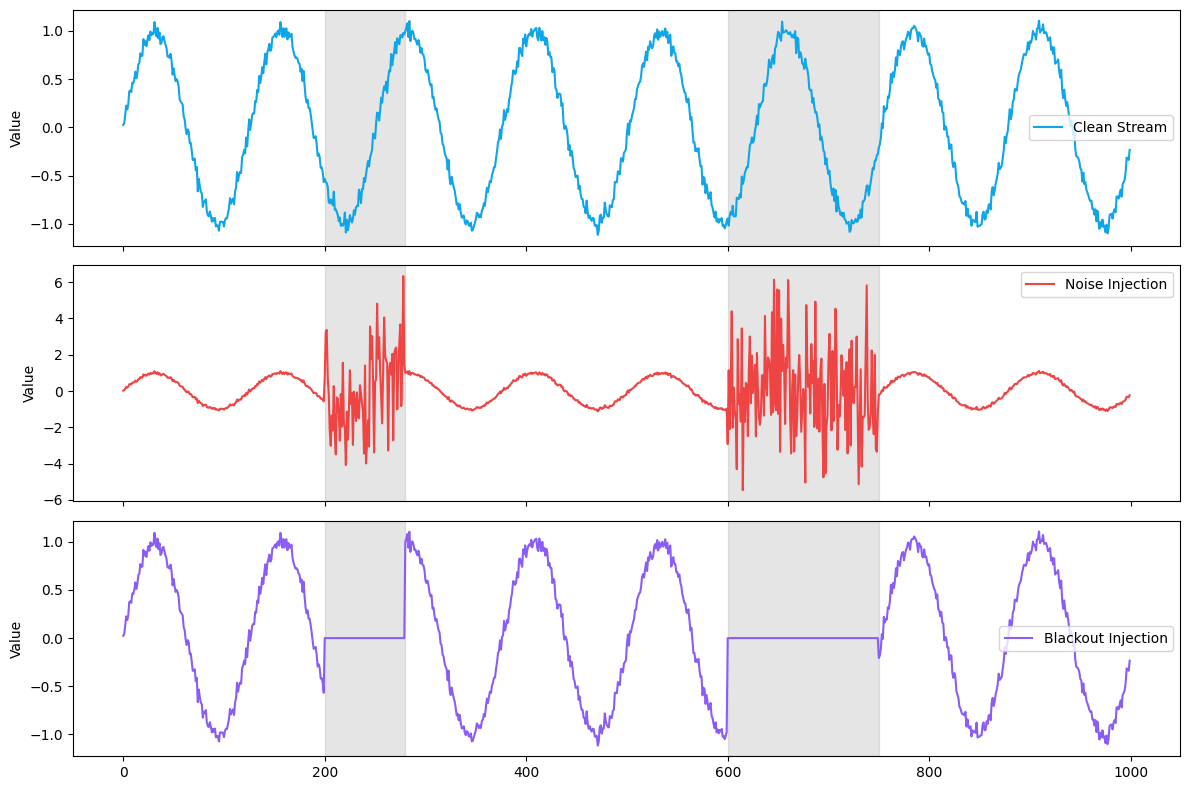

Plot saved.


In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
t = np.arange(1000)

# TODO: Plot clean stream on axes[0]
# your code here
axes[0].plot(
    t,
    clean_stream[:,0],
    color='#0EA5E9',
    label='Clean Stream'
)

# TODO: Plot noisy stream on axes[1]
# your code here
axes[1].plot(
    t,
    noisy_stream[:,0],
    color='#EF4444',
    label='Noise Injection'
)

# TODO: Plot blackout stream on axes[2]
# your code here
axes[2].plot(
    t,
    blackout_stream[:,0],
    color='#8B5CF6',
    label='Blackout Injection'
)

# TODO: Add overall figure title and save
# your code here
for ax in axes:
    for start, end in windows:
        ax.axvspan(
            start,
            end,
            color='gray',
            alpha=0.2
        )

    ax.legend()
    ax.set_ylabel('Value')

plt.tight_layout()
plt.savefig('week03_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved.')

Q1. Compare the two injection modes visually. What does each mode look like inside the anomaly windows, and how would an autoencoder’s reconstruction error differ between them?

The clean stream looks normal. It shows the stream of data operating as it should both in and out of the  windows. The noise injection stream becomes super jagged within both of the windows and has it spike higher and lower than normal. The blackout injection just stops recording data inside the windows. The data flatlines at zero. Both the jammed and blackout injection's would read reconstruction errors, but the blackout may read larger reconstruction errors since it lost all data.

Q2. The two anomaly windows have different lengths (80 and 150 timesteps). Does inject_noise_profile() require any modification to handle variable-length windows? Explain why or why not.

No modifications are needed to the inject_noise_profile(). The function will automaticly always start and end the window using the end_idx and start_idx.

Q3. Suppose the SKAB file you load has no anomaly windows (all anomaly labels are 0). What does extract_anomaly_windows() return, and what happens when you iterate over that return value in the injection loop?

If all the anonalies are zero, then extract_anomaly_window() will return an empty list. When the inject loop goes over this list, nothing will happen or change.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
